# 40 — Experimento mix_small_medium: uma classe para os navios abaixo de 100 m

**Pergunta.** No NB39, os modelos não separaram SMALL de MEDIUM em navios novos. Se SMALL e MEDIUM virarem **uma só classe**, chamada **MIX_SMALL_MEDIUM** (todo navio com menos de 100 m), o modelo reconhece essa classe em navios que nunca ouviu?

**Classes deste experimento:**

| Classe | O que inclui |
|---|---|
| **MIX_SMALL_MEDIUM** | as classes SMALL e MEDIUM do IARA (navios de 8 a 98 m) |
| **LARGE** | igual ao IARA (navios a partir de 100 m) |
| **BACKGROUND** | igual ao IARA (mar sem navio, subconjunto E) |

**Modelo:** a mesma MLP h32-16 do NB29 (mesmos hiperparâmetros, folds e sementes), **treinada do zero** com os rótulos acima (`scratch/mix_small_medium/treino_mlp.py`). A única mudança é a definição das classes.

**Resumo das respostas:**
1. **Sim, MIX_SMALL_MEDIUM generaliza.** Em navios nunca vistos, o recall de MIX_SMALL_MEDIUM é **76%**; no split por gravação, 82%. Perda de só 6 pontos (com as classes do IARA, MEDIUM perdia ~31).
2. **Treinar com os rótulos novos dá o mesmo que juntar as previsões do modelo antigo** (ACC 74,6 × 75,1, p = 0,496). O modelo antigo já tinha aprendido "navio < 100 m"; só não separava SMALL de MEDIUM.
3. **O erro agora está na fronteira de 100 m:** LARGE de 100–150 m é prevista MIX_SMALL_MEDIUM em 52% das gravações, contra 22% para LARGE acima de 250 m. Diferente de SMALL × MEDIUM, aqui há um gradiente de tamanho.
4. **A razão está no som (seção 6):** navios < 100 m têm o pico de energia entre 90 e 221 Hz, os LARGE abaixo de 90 Hz, e o grave dos LARGE cresce na passagem pelo CPA. Entre SMALL e MEDIUM, nenhuma faixa difere (0 diferenças confiáveis em 140 testes; MEDIUM × LARGE: 91).

**Atenção:** com 3 classes o acaso é 33% (com as classes do IARA, 25%). O SP deste experimento **não é comparável** ao SP do artigo. É um diagnóstico de até onde o IARA permite generalizar hoje, não uma melhora do SP do IARA.

## Glossário rápido

- **Split por gravação (artigo):** treino e teste dividem as gravações; o *mesmo navio* pode ter gravações dos dois lados.
- **Split por navio:** nenhum navio aparece no treino e no teste ao mesmo tempo. Mede o acerto em navios que o modelo nunca ouviu. São os folds do NB29 (`reports/split_navio/folds.csv`).
- **Recall de uma classe:** % das gravações daquela classe que o modelo acerta.
- **ACC (acurácia balanceada):** média dos recalls das classes. **SP:** índice do artigo (média aritmética e geométrica dos recalls), aqui calculado sobre as 3 classes deste experimento.
- **Valor-p (teste F 5x2cv):** chance de ver uma diferença dessas se os dois métodos fossem equivalentes; abaixo de 0,05, a diferença provavelmente é real.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
try:
    from IPython.display import display
except ImportError:
    display = print
for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 1); pd.set_option('display.width', 200)

CN = {0: 'SMALL', 1: 'MEDIUM', 2: 'LARGE', 3: 'BACKGROUND'}          # classes do IARA
CM = {0: 'MIX_SMALL_MEDIUM', 1: 'LARGE', 2: 'BACKGROUND'}             # classes do mix_small_medium
MAPA = {0: 0, 1: 0, 2: 1, 3: 2}                                      # IARA -> mix_small_medium
COR = {'MIX_SMALL_MEDIUM': '#2a78d6', 'LARGE': '#1baf7a', 'BACKGROUND': '#8a8a8a'}

meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta = meta[meta.Dataset.isin(list('ABCDE'))].copy()
meta.index = meta.ID.astype(int); meta['Ship ID'] = meta['Ship ID'].str.strip()
meta['Length'] = pd.to_numeric(meta.Length, errors='coerce')
meta['Target'] = np.select([meta.Length < 50, meta.Length < 100, meta.Length >= 100], [0, 1, 2], default=3)
meta.loc[meta.Dataset == 'E', 'Target'] = 3
meta['Classe IARA'] = meta.Target.map(CN)
meta['Classe mix'] = meta.Target.map(MAPA).map(CM)
meta['Recording time'] = pd.to_numeric(meta['Recording time'], errors='coerce')

def tipo(r):
    t = r['DETAILED TYPE']
    if r.Target == 0: return {'Pilot Vessel': 'SMALL: prático', 'Tug': 'SMALL: rebocador', 'Fishing Vessel': 'SMALL: pesca'}.get(t, 'SMALL: outros')
    if r.Target == 1: return {'Motor Hopper': 'MEDIUM: draga (HANG BO)', 'Offshore Supply Ship': 'MEDIUM: OSS'}.get(t, 'MEDIUM: outros supply/AHTS')
    return '-'
meta['Tipo'] = meta.apply(tipo, axis=1)

def previsoes(exp, juntar=False):
    """{fold: DataFrame(File, Target, Prediction)} por gravação; juntar=True converte um experimento de 4 classes do IARA."""
    out = {}
    for k, d in R.file_predictions(exp).items():
        d = d.copy(); d['File'] = d.File.astype(int)
        if juntar:
            d['Target'] = d.Target.map(MAPA); d['Prediction'] = d.Prediction.map(MAPA)
        out[k] = d
    return out

def metricas(y, p):
    rec = np.array([np.mean(p[y == c] == c) for c in range(3)])
    sp = np.sqrt(rec.mean() * np.exp(np.mean(np.log(rec)))) * 100 if np.all(rec > 0) else 0.0
    return {'SP': sp, 'ACC': rec.mean() * 100, **{f'R_{CM[c]}': r * 100 for c, r in enumerate(rec)}}

def por_fold(prev):
    return pd.DataFrame({k: metricas(d.Target.values, d.Prediction.values) for k, d in prev.items()}).T

SPLITS = {'split_navio': 'por navio', 'split_id': 'por gravação (artigo)'}
NOVO = {c: previsoes(f'mix_small_medium_{c}_mlp_lofar') for c in SPLITS}
JUNT = {c: previsoes(f'{c}_mlp_lofar_4c', juntar=True) for c in SPLITS}
print('Experimentos carregados:', [f'mix_small_medium_{c}_mlp_lofar' for c in SPLITS])

Experimentos carregados: ['mix_small_medium_split_navio_mlp_lofar', 'mix_small_medium_split_id_mlp_lofar']


## 1. Motivação: o modelo não separa SMALL de MEDIUM em navios novos

Matriz de confusão da MLP LOFAR do NB29, com as classes do IARA e split por navio.

In [2]:
P = pd.concat(R.file_predictions('split_navio_mlp_lofar_4c').values(), ignore_index=True)
MOT = pd.crosstab(P.Target.map(CN), P.Prediction.map(CN), normalize='index').mul(100)
MOT = MOT.loc[list(CN.values()), list(CN.values())]
MOT.index.name = 'verdadeira'; MOT.columns.name = 'prevista'
print('MLP LOFAR do NB29, classes do IARA, split por navio: % das gravações de cada classe verdadeira')
display(MOT.round(1))

MLP LOFAR do NB29, classes do IARA, split por navio: % das gravações de cada classe verdadeira


prevista,SMALL,MEDIUM,LARGE,BACKGROUND
verdadeira,,,,
SMALL,48.9,22.9,23.9,4.2
MEDIUM,51.0,32.3,15.3,1.4
LARGE,20.3,10.5,67.7,1.6
BACKGROUND,11.3,4.3,3.3,81.1


**Leitura.** Uma gravação MEDIUM de navio novo é prevista SMALL em **51%** dos casos, tanto quanto uma SMALL (49%). Mas SMALL e MEDIUM quase nunca são confundidas com BACKGROUND (4% e 1%). O modelo parece ter aprendido "navio menor" sem saber dizer se é SMALL ou MEDIUM.

## 2. As classes do experimento mix_small_medium

In [3]:
INV = {}
for c in [0, 1, 2]:
    d = meta[meta.Target.map(MAPA) == c]
    n = d.groupby('Ship ID').size(); p = n / n.sum()
    INV[CM[c]] = {'gravações': len(d), 'horas': d['Recording time'].sum() / 3600,
                  'navios distintos': len(n) if c < 2 else np.nan, 'nº efetivo de navios': 1 / (p ** 2).sum() if c < 2 else np.nan,
                  'comprimento (m)': f"{d.Length.min():.0f}–{d.Length.max():.0f}" if c < 2 else '-'}
INV = pd.DataFrame(INV)
display(INV)

,MIX_SMALL_MEDIUM,LARGE,BACKGROUND
gravações,873,572,261
horas,66.8,44.2,10.9
navios distintos,169,417,NaN
nº efetivo de navios,24.3,213.6,NaN
comprimento (m),8–98,100–349,-


**Leitura.** MIX_SMALL_MEDIUM tem 873 gravações de 169 navios distintos, mas o nº efetivo de navios é só **24,3** (LARGE: 214), porque as lanchas de prático e as dragas HANG BO continuam dominando. Juntar as classes dobra a diversidade de navios em relação a SMALL ou MEDIUM sozinhas (~12 cada), mas continua bem abaixo de LARGE.

## 3. Resultados

Para cada split, comparo:
- **MLP mix_small_medium:** treinada do zero com os rótulos MIX_SMALL_MEDIUM, LARGE e BACKGROUND;
- **MLP do NB29 juntada:** a MLP treinada com as classes do IARA, com as previsões SMALL e MEDIUM juntadas em MIX_SMALL_MEDIUM **depois** do treino.

A diferença entre as duas mostra se treinar com os rótulos novos ensina algo a mais.

SP         ACC R_MIX_SMALL_MEDIUM     R_LARGE R_BACKGROUND
split                 modelo                                                                                                           
por navio             MLP mix_small_medium (treinada com 3 rótulos)  74.5 ± 1.0  74.6 ± 1.0         76.2 ± 3.8  67.7 ± 3.3   79.9 ± 4.2
                      MLP do NB29 com SMALL+MEDIUM juntados depois   75.0 ± 1.1  75.1 ± 1.1         76.6 ± 4.9  67.7 ± 4.3   81.1 ± 3.5
por gravação (artigo) MLP mix_small_medium (treinada com 3 rótulos)  78.0 ± 0.9  78.1 ± 0.8         82.4 ± 2.8  70.6 ± 4.1   81.5 ± 1.4
                      MLP do NB29 com SMALL+MEDIUM juntados depois   77.7 ± 1.1  77.8 ± 1.1         82.3 ± 1.8  71.2 ± 3.4   80.0 ± 2.0

MLP mix_small_medium − MLP do NB29 juntada:


,Δ ACC,p (F 5x2cv),folds melhores,Δ recall MIX_SMALL_MEDIUM,Δ recall LARGE
por navio,-0.5,0.5,3.0,-4.0e-01,-2.0e-02
por gravação (artigo),0.3,0.7,5.0,4.9e-02,-5.8e-01


MLP mix_small_medium: split por gravação -> split por navio


,por gravação,por navio,queda
SP,78.0,74.5,3.6
ACC,78.1,74.6,3.5
R_MIX_SMALL_MEDIUM,82.4,76.2,6.1
R_LARGE,70.6,67.7,2.9
R_BACKGROUND,81.5,79.9,1.5


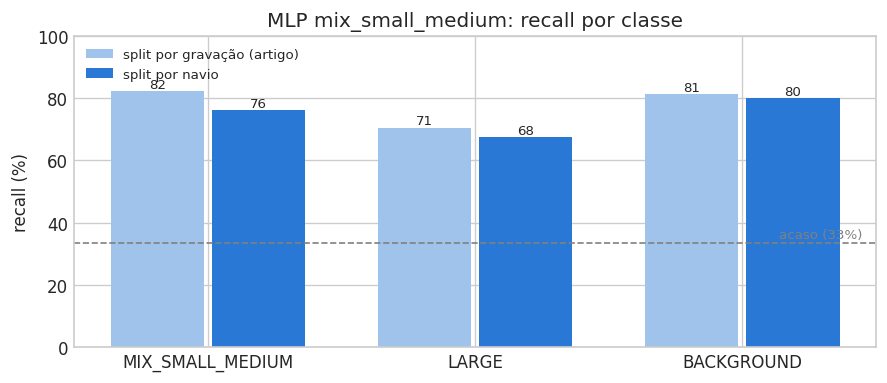

In [4]:
rows, FM = [], {}
for c, rot in SPLITS.items():
    for mod, prev in [('MLP mix_small_medium (treinada com 3 rótulos)', NOVO[c]), ('MLP do NB29 com SMALL+MEDIUM juntados depois', JUNT[c])]:
        fm = por_fold(prev); FM[(c, mod)] = fm
        rows.append({'split': rot, 'modelo': mod, **{f'{m}': f"{fm[m].mean():.1f} ± {fm[m].std(ddof=0):.1f}" for m in fm.columns}})
RES = pd.DataFrame(rows).set_index(['split', 'modelo'])
display(RES)
NOVO_M = {c: FM[(c, 'MLP mix_small_medium (treinada com 3 rótulos)')].mean() for c in SPLITS}
JUNT_M = {c: FM[(c, 'MLP do NB29 com SMALL+MEDIUM juntados depois')].mean() for c in SPLITS}

# treinar com os novos rótulos x juntar as previsões do modelo de 4 classes (mesmos folds, teste F 5x2cv)
COMP = {}
for c in SPLITS:
    a, b = FM[(c, 'MLP mix_small_medium (treinada com 3 rótulos)')], FM[(c, 'MLP do NB29 com SMALL+MEDIUM juntados depois')]
    COMP[SPLITS[c]] = {'Δ ACC': (a.ACC - b.ACC).mean(), 'p (F 5x2cv)': R.f_test_5x2(a.ACC.values, b.ACC.values)[1],
                       'folds melhores': int(((a.ACC - b.ACC) > 0).sum()),
                       'Δ recall MIX_SMALL_MEDIUM': (a.R_MIX_SMALL_MEDIUM - b.R_MIX_SMALL_MEDIUM).mean(),
                       'Δ recall LARGE': (a.R_LARGE - b.R_LARGE).mean()}
COMP = pd.DataFrame(COMP).T
print('MLP mix_small_medium − MLP do NB29 juntada:'); display(COMP.round(3))

# perda de generalização: split por gravação -> split por navio
QUEDA = pd.DataFrame({'por gravação': NOVO_M['split_id'], 'por navio': NOVO_M['split_navio']})
QUEDA['queda'] = QUEDA['por gravação'] - QUEDA['por navio']
print('MLP mix_small_medium: split por gravação -> split por navio'); display(QUEDA.round(1))

fig, ax = plt.subplots(figsize=(7.5, 3.3))
x = np.arange(3); w = 0.38
for i, (c, cor) in enumerate([('split_id', '#9fc3ea'), ('split_navio', '#2a78d6')]):
    v = [NOVO_M[c][f'R_{CM[j]}'] for j in range(3)]
    b = ax.bar(x + (i - 0.5) * w, v, w * 0.92, color=cor, label=f'split {SPLITS[c]}')
    for xi, vi in zip(x + (i - 0.5) * w, v):
        ax.text(xi, vi + 1, f'{vi:.0f}', ha='center', fontsize=8)
ax.axhline(100 / 3, color='gray', ls='--', lw=1); ax.text(2.45, 35, 'acaso (33%)', fontsize=8, color='gray', ha='right')
ax.set_xticks(x); ax.set_xticklabels(list(CM.values())); ax.set_ylabel('recall (%)'); ax.set_ylim(0, 100)
ax.set_title('MLP mix_small_medium: recall por classe'); ax.legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

**Leitura.**
- **MIX_SMALL_MEDIUM generaliza:** recall de **76,2%** em navios nunca vistos, contra 82,4% no split por gravação, perda de 6,1 pontos. Para comparação, com as classes do IARA o recall de MEDIUM cai de ~66% para ~35% (NB39). LARGE (68%) e BACKGROUND (80%) perdem 2,9 e 1,5 pontos.
- **Split por navio: SP 74,5, ACC 74,6.** O acaso é 33%.
- **Treinar com os rótulos novos não muda nada:** no split por navio, Δ ACC = -0,52 (p = 0,496, melhor em 3 de 10 folds); no split por gravação, Δ ACC = 0,31 (p = 0,715). O modelo das 4 classes do IARA já separava "navio < 100 m" de LARGE e de BACKGROUND; o que ele não conseguia era a divisão interna.

## 4. Matrizes de confusão

In [5]:
CONF = {}
for c, rot in SPLITS.items():
    d = pd.concat(NOVO[c].values(), ignore_index=True)
    t = pd.crosstab(d.Target.map(CM), d.Prediction.map(CM), normalize='index').mul(100)
    CONF[c] = t.loc[list(CM.values()), list(CM.values())]
    CONF[c].index.name = 'verdadeira'; CONF[c].columns.name = 'prevista'
    print(f'Matriz de confusão (% da classe verdadeira), split {rot}:'); display(CONF[c].round(1))

Matriz de confusão (% da classe verdadeira), split por navio:


prevista,MIX_SMALL_MEDIUM,LARGE,BACKGROUND
verdadeira,,,
MIX_SMALL_MEDIUM,76.2,21.3,2.5
LARGE,30.9,67.6,1.6
BACKGROUND,15.9,4.1,79.9


Matriz de confusão (% da classe verdadeira), split por gravação (artigo):


prevista,MIX_SMALL_MEDIUM,LARGE,BACKGROUND
verdadeira,,,
MIX_SMALL_MEDIUM,82.4,15.6,2.0
LARGE,27.8,70.6,1.6
BACKGROUND,15.0,3.5,81.5


**Leitura.** O erro principal, em navios novos, é a troca entre MIX_SMALL_MEDIUM e LARGE: 21% das MIX_SMALL_MEDIUM vão para LARGE e 31% das LARGE vão para MIX_SMALL_MEDIUM. BACKGROUND quase não é confundido com LARGE, mas 16% dele é previsto MIX_SMALL_MEDIUM.

## 5. Onde a MLP mix_small_medium erra (split por navio)

Recall de MIX_SMALL_MEDIUM pela classe original do IARA e pelo tipo de navio; e os erros pelo comprimento do navio, para ver se se concentram perto da nova fronteira de 100 m.

Recall de MIX_SMALL_MEDIUM pela classe original do IARA (split por navio):


,gravações,navios,acerto,prev_LARGE,prev_BG
Classe IARA,,,,,
MEDIUM,397,82,81.5,17.5,1.0
SMALL,476,87,71.9,24.4,3.7


Por tipo de navio:


,navios,avaliações,acerto,prev_LARGE
Tipo,,,,
MEDIUM: OSS,46,695,84.3,15.3
MEDIUM: draga (HANG BO),3,735,82.4,16.9
MEDIUM: outros supply/AHTS,33,555,76.6,21.3
SMALL: outros,16,175,86.3,13.7
SMALL: pesca,22,165,67.9,29.1
SMALL: prático,15,1605,71.0,24.7
SMALL: rebocador,34,435,71.0,26.0


MIX_SMALL_MEDIUM por comprimento (split por navio):


,navios,acerto,prev_LARGE
0–25 m,46,70.7,25.3
25–50 m,41,76.2,21.3
50–75 m,28,82.1,17.4
75–100 m,54,80.7,17.7


LARGE por comprimento (split por navio):


,navios,acerto,prev_MIX
100–150 m,39,44.9,51.7
150–200 m,103,62.0,36.4
200–250 m,80,67.4,32.6
250–400 m,195,76.0,22.2


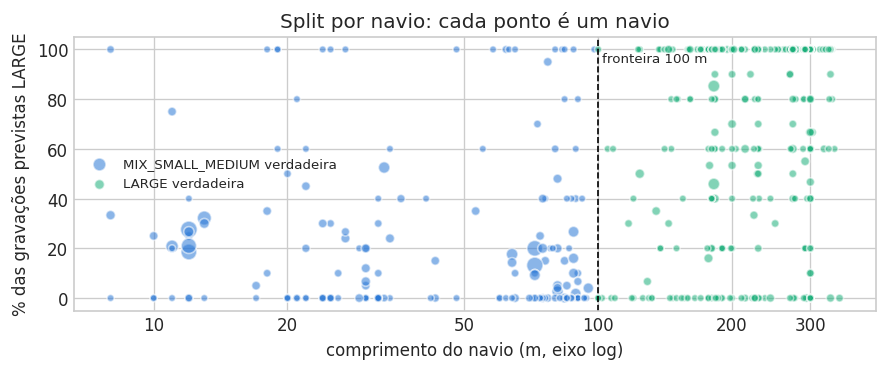

In [6]:
d = pd.concat([v.assign(fold=k) for k, v in NOVO['split_navio'].items()], ignore_index=True)
d = d.join(meta[['Classe IARA', 'Tipo', 'Length', 'Ship ID']], on='File'); d['ok'] = d.Target == d.Prediction
d['prev'] = d.Prediction.map(CM)
mix = d[d.Target == 0]
POR_CLASSE = mix.groupby('Classe IARA').agg(gravações=('File', 'nunique'), navios=('Ship ID', 'nunique'), acerto=('ok', 'mean'),
                                            prev_LARGE=('prev', lambda s: (s == 'LARGE').mean()), prev_BG=('prev', lambda s: (s == 'BACKGROUND').mean()))
POR_CLASSE[['acerto', 'prev_LARGE', 'prev_BG']] *= 100
print('Recall de MIX_SMALL_MEDIUM pela classe original do IARA (split por navio):'); display(POR_CLASSE.round(1))
POR_TIPO = mix.groupby('Tipo').agg(navios=('Ship ID', 'nunique'), avaliações=('ok', 'size'), acerto=('ok', 'mean'),
                                   prev_LARGE=('prev', lambda s: (s == 'LARGE').mean()))
POR_TIPO[['acerto', 'prev_LARGE']] *= 100
print('Por tipo de navio:'); display(POR_TIPO.round(1))

# a nova fronteira é 100 m: os erros se concentram perto dela?
FX_MIX = mix.groupby(pd.cut(mix.Length, [0, 25, 50, 75, 100], right=False), observed=True).agg(
    navios=('Ship ID', 'nunique'), acerto=('ok', 'mean'), prev_LARGE=('prev', lambda s: (s == 'LARGE').mean()))
FX_MIX[['acerto', 'prev_LARGE']] *= 100; FX_MIX.index = [f'{i.left:g}–{i.right:g} m' for i in FX_MIX.index]
lg = d[d.Target == 1]
FX_LG = lg.groupby(pd.cut(lg.Length, [100, 150, 200, 250, 400], right=False), observed=True).agg(
    navios=('Ship ID', 'nunique'), acerto=('ok', 'mean'), prev_MIX=('prev', lambda s: (s == 'MIX_SMALL_MEDIUM').mean()))
FX_LG[['acerto', 'prev_MIX']] *= 100; FX_LG.index = [f'{i.left:g}–{i.right:g} m' for i in FX_LG.index]
print('MIX_SMALL_MEDIUM por comprimento (split por navio):'); display(FX_MIX.round(1))
print('LARGE por comprimento (split por navio):'); display(FX_LG.round(1))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
nav = d[d.Target < 2].groupby('Ship ID').agg(L=('Length', 'first'), n=('File', 'nunique'),
                                              y=('Target', 'first'), prevL=('prev', lambda s: (s == 'LARGE').mean() * 100))
for y, cor, rot in [(0, COR['MIX_SMALL_MEDIUM'], 'MIX_SMALL_MEDIUM verdadeira'), (1, COR['LARGE'], 'LARGE verdadeira')]:
    s = nav[nav.y == y]
    ax.scatter(s.L, s.prevL, s=8 + 10 * np.sqrt(s.n), color=cor, alpha=0.55, edgecolor='white', label=rot)
ax.axvline(100, color='k', ls='--', lw=1); ax.text(102, 95, 'fronteira 100 m', fontsize=8)
ax.set_xscale('log'); ax.set_xticks([10, 20, 50, 100, 200, 300]); ax.set_xticklabels(['10', '20', '50', '100', '200', '300'])
ax.set_xlabel('comprimento do navio (m, eixo log)'); ax.set_ylabel('% das gravações previstas LARGE')
ax.set_title('Split por navio: cada ponto é um navio'); ax.legend(fontsize=8, loc='center left')
plt.tight_layout(); plt.show()

**Leitura.**
- **A parte MEDIUM acerta mais que a parte SMALL:** 81% × 72%. Quando erra uma SMALL, o modelo diz LARGE (24%), o mesmo padrão das lanchas de prático com graves fortes (NB39, seção 9).
- **Todos os tipos ficam acima de 65%,** inclusive os que tinham poucos navios: pesca 68%, prático 71%, rebocador 71%, OSS 84%, dragas 82%.
- **Do lado LARGE, há um gradiente de tamanho:** LARGE de 100–150 m vira MIX_SMALL_MEDIUM em **52%** das gravações, de 150–200 m em 36%, de 200–250 m em 33% e acima de 250 m em 22%. Ao contrário da fronteira de 50 m (NB39, seção 10), o modelo capta alguma relação entre tamanho e som nessa escala.
- **Do lado MIX_SMALL_MEDIUM, o gradiente é fraco e invertido:** os navios mais curtos (até 25 m) vão mais para LARGE (25%) que os de 75–100 m (18%). Isso vem das lanchas de prático com graves fortes, não de tamanho.

## 6. Por que MIX_SMALL_MEDIUM e LARGE se separam, e SMALL e MEDIUM não

O experimento mostra que o modelo separa "navio < 100 m" de LARGE, mas não SMALL de MEDIUM. Esta seção procura **no som** a razão disso: em que faixas de frequência, e em que momento da passagem, as classes diferem.

**Como foi medido.**
- Só gravações com CPA (subconjuntos A e C), para poder alinhar todas pelo instante em que o navio passa mais perto.
- O LOFAR de cada gravação (dB acima do fundo TPSW) é cortado em **10 fatias de 30 s**, de 150 s antes a 150 s depois do CPA, e resumido em **14 faixas de frequência** de 15 Hz a 8 kHz.
- Cada navio vira **um ponto** (média das suas gravações), para que navios com muitas gravações não pesem mais.
- Para cada par de classes, fatia e faixa: **AUC**, a % das comparações navio × navio em que a 2ª classe tem mais energia (50% = empate, como cara ou coroa). Teste de Mann-Whitney e correção para 140 testes (FDR).

797 gravações com CPA (A e C); 10 fatias de 30 s (−150 a +150 s) × 14 faixas; um ponto por navio


,testes (fatia × faixa),"diferenças confiáveis (q < 0,05)","p < 0,05",esperado só por acaso
SMALL × MEDIUM,140,0,13,7
MEDIUM × LARGE,140,91,94,7
SMALL × LARGE,140,100,104,7


Quem tem mais energia na faixa, % das comparações navio × navio que ganha (fatias com diferença confiável de 10):


,SMALL × MEDIUM,MEDIUM × LARGE,SMALL × LARGE
23-37 Hz,empate (0/10),LARGE 54–66% (7/10),LARGE 70–76% (10/10)
37-58 Hz,empate (0/10),LARGE 75–82% (10/10),LARGE 75–85% (10/10)
58-90 Hz,empate (0/10),LARGE 64–79% (10/10),LARGE 57–74% (9/10)
90-141 Hz,empate (0/10),MEDIUM 61–69% (10/10),SMALL 62–71% (10/10)
141-221 Hz,empate (0/10),MEDIUM 70–79% (10/10),SMALL 70–76% (10/10)
5109-8000 Hz,empate (0/10),LARGE 72–77% (10/10),LARGE 60–67% (10/10)


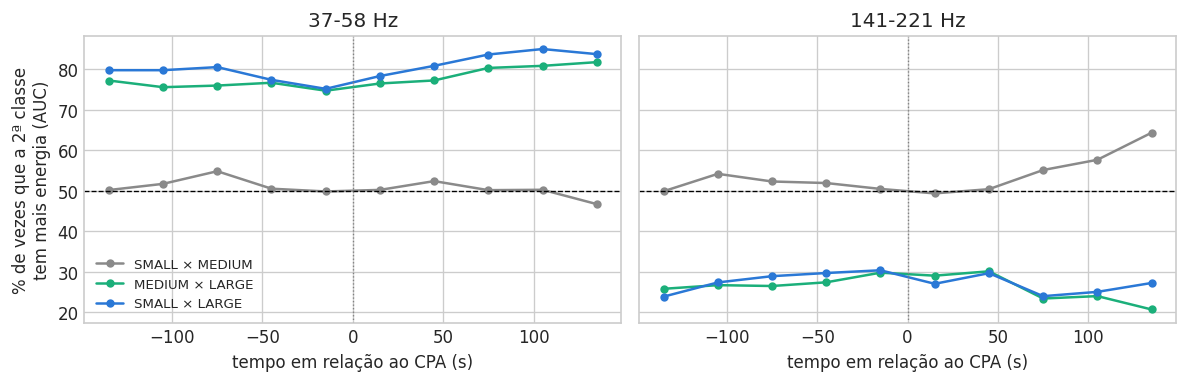

In [7]:
from scipy import stats as st
for _p in (os.path.join(R.ROOT, 'scratch'), os.path.join(R.ROOT, 'scratch', 'apres_small_medium')):
    if _p not in sys.path: sys.path.insert(0, _p)
import eval_ship_split_5x2cv as E5
if not os.path.isabs(E5.META): E5.META = os.path.join(R.ROOT, E5.META)
import cpa_fatias as CF
CF.LOFAR_DIR = os.path.join(R.ROOT, 'data/iara_processed/lofar_bc1559516c522e2b993895bf5cb2ac94')
CF.CACHE = os.path.join(R.ROOT, 'data/iara_processed/cache_lofar_cpa_fatias.pkl')
mcf = CF.metadata()
DCF = CF.build(mcf)          # LOFAR por quadro (dB acima do fundo TPSW) em fatias de 30 s em torno do CPA; só A e C
PARES = {'SMALL × MEDIUM': (0, 1), 'MEDIUM × LARGE': (1, 2), 'SMALL × LARGE': (0, 2)}
TCF = {k: CF.compara(DCF, mcf, a, b) for k, (a, b) in PARES.items()}
CONT = pd.DataFrame({k: {'testes (fatia × faixa)': len(T), 'diferenças confiáveis (q < 0,05)': int((T.q < .05).sum()),
                         'p < 0,05': int((T.p < .05).sum()), 'esperado só por acaso': round(.05 * len(T))}
                     for k, T in TCF.items()}).T
print(f'{DCF.File.nunique()} gravações com CPA (A e C); 10 fatias de 30 s (−150 a +150 s) × 14 faixas; um ponto por navio')
display(CONT)

# quem tem mais energia em cada faixa e com que frequência ganha a comparação navio × navio (AUC -> %)
FX = ['23-37', '37-58', '58-90', '90-141', '141-221', '5109-8000']
def quem(T, b, a_nome, b_nome):
    x = T[T.banda == b]; lo, hi = x.AUC.min(), x.AUC.max(); n = int((x.q < .05).sum())
    if n == 0: return f'empate ({n}/10)'
    return f'{b_nome} {lo*100:.0f}–{hi*100:.0f}% ({n}/10)' if x.AUC.median() > .5 else f'{a_nome} {(1-hi)*100:.0f}–{(1-lo)*100:.0f}% ({n}/10)'
GANHA = pd.DataFrame({k: {f'{b} Hz': quem(TCF[k], b, *k.split(' × ')) for b in FX} for k in PARES})
print('Quem tem mais energia na faixa, % das comparações navio × navio que ganha (fatias com diferença confiável de 10):')
display(GANHA)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
xs = (CF.SL[:-1] + CF.SL[1:]) / 2
for ax, b in zip(axs, ['37-58', '141-221']):
    for k, cor in [('SMALL × MEDIUM', '#8a8a8a'), ('MEDIUM × LARGE', '#1baf7a'), ('SMALL × LARGE', '#2a78d6')]:
        y = TCF[k][TCF[k].banda == b].set_index('fatia').reindex(CF.SNAMES).AUC * 100
        ax.plot(xs, y, marker='o', ms=4, color=cor, label=k)
    ax.axhline(50, color='k', lw=.8, ls='--'); ax.axvline(0, color='gray', lw=.8, ls=':')
    ax.set_title(f'{b} Hz'); ax.set_xlabel('tempo em relação ao CPA (s)')
axs[0].set_ylabel('% de vezes que a 2ª classe\ntem mais energia (AUC)'); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.**
- **SMALL × MEDIUM: 0 diferenças confiáveis em 140.** Nenhuma faixa, em nenhum momento da passagem. "Empate" não quer dizer energia igual: quer dizer que, sorteando um navio de cada classe, cada um ganha em cerca de metade das vezes.
- **MEDIUM × LARGE: 91/140; SMALL × LARGE: 100/140.** E o "desenho" é o mesmo para SMALL e MEDIUM: os LARGE têm mais energia **abaixo de ~90 Hz** (37–58 Hz, LARGE ganha em 75–85% das comparações) e os navios menores têm mais **entre 90 e 221 Hz** (ganham em 61–79%). É por isso que juntar SMALL e MEDIUM funciona.
- **Nos LARGE, a diferença cresce depois do CPA** (gráfico da esquerda): é o comportamento esperado para som do próprio navio.
- Nos agudos (5–8 kHz) há uma tendência a favor dos LARGE, mas com diferenças minúsculas em dB; quem separa as classes, na prática, são os graves de 23 a 221 Hz.

### 6.1 A diferença MEDIUM × LARGE pode ser acaso ou viés?

Três verificações: (1) embaralhar os rótulos MEDIUM/LARGE entre navios 1000 vezes; (2) dividir os navios em duas metades sem navio em comum, 100 vezes, e conferir se a diferença de uma metade aparece na outra; (3) repetir só com A (CPA até 250 m) e só com C (250–500 m).

In [8]:
# MEDIUM × LARGE: (1) embaralhar rótulos entre navios; (2) metades de navios; (3) A e C separados
CEL = [('-30..+0', '37-58'), ('+90..+120', '37-58'), ('-30..+0', '141-221'), ('-30..+0', '5109-8000')]
dml = DCF.join(mcf[['Target', 'Ship ID']], on='File'); dml = dml[dml.Target.isin([1, 2])]
navml = dml.groupby(['fatia', 'Ship ID']).agg({**{b: 'mean' for b in CF.BNAMES}, 'Target': 'first'}).reset_index()
def auc(x, y, col):
    u, v = x[y == 2][col].values, x[y == 1][col].values
    return st.mannwhitneyu(u, v).statistic / (len(u) * len(v))
rng = np.random.default_rng(0); rows = []
for s, b in CEL:
    x = navml[navml.fatia == s]; y = x.Target.values; obs = auc(x, y, b)
    null = np.array([auc(x, rng.permutation(y), b) for _ in range(1000)])
    rows.append({'fatia': s, 'faixa': b, 'AUC real': obs, 'embaralhado 2,5%': np.percentile(null, 2.5),
                 'embaralhado 97,5%': np.percentile(null, 97.5), 'acaso igualou (de 1000)': int((np.abs(null - .5) >= abs(obs - .5)).sum())})
PERM = pd.DataFrame(rows)
ships = dml.groupby('Ship ID').Target.first(); res = {c: [] for c in CEL}
for _ in range(100):
    h = set()
    for c in [1, 2]:
        sh = ships[ships == c].index.values; h |= set(rng.choice(sh, len(sh) // 2, replace=False))
    Ta = CF.compara(DCF, mcf, 1, 2, ships=h).set_index(['fatia', 'banda'])
    Tb = CF.compara(DCF, mcf, 1, 2, ships=set(ships.index) - h).set_index(['fatia', 'banda'])
    for k in CEL:
        res[k].append((np.sign(Ta.loc[k, 'AUC'] - .5) == np.sign(Tb.loc[k, 'AUC'] - .5), Tb.loc[k, 'p'] < .05, Tb.loc[k, 'AUC']))
PERM['mesmo sentido nas metades (%)'] = [100 * np.mean([r[0] for r in res[k]]) for k in CEL]
PERM['p<0,05 na outra metade (%)'] = [100 * np.mean([r[1] for r in res[k]]) for k in CEL]
for ds in 'AC':
    T = CF.compara(DCF[DCF.File.isin(mcf.index[mcf.Dataset == ds])], mcf, 1, 2).set_index(['fatia', 'banda'])
    PERM[f'AUC só {ds}'] = [T.loc[k, 'AUC'] for k in CEL]
    PERM.attrs[f'sig_{ds}'] = int((T.q < .05).sum())
print('MEDIUM × LARGE: o resultado pode ser acaso, poucos navios ou distância?')
display(PERM.round(2))
print(f"Diferenças confiáveis só em A: {PERM.attrs['sig_A']}/140; só em C: {PERM.attrs['sig_C']}/140")

MEDIUM × LARGE: o resultado pode ser acaso, poucos navios ou distância?


,fatia,faixa,AUC real,"embaralhado 2,5%","embaralhado 97,5%",acaso igualou (de 1000),mesmo sentido nas metades (%),"p<0,05 na outra metade (%)",AUC só A,AUC só C
0,-30..+0,37-58,0.8,0.4,0.6,0,100.0,100.0,0.8,0.7
1,+90..+120,37-58,0.8,0.4,0.6,0,100.0,100.0,0.9,0.8
2,-30..+0,141-221,0.3,0.4,0.6,0,100.0,99.0,0.3,0.3
3,-30..+0,5109-8000,0.8,0.4,0.6,0,100.0,100.0,0.8,0.8


Diferenças confiáveis só em A: 85/140; só em C: 59/140


**Leitura.**
- **Acaso descartado:** com os rótulos embaralhados, a AUC fica entre 41% e 59%; o acaso nunca chegou ao valor real (0 vezes em 4 × 1000).
- **Não depende de alguns navios:** a diferença aparece no mesmo sentido nas duas metades em 100% dos sorteios, e é significativa na outra metade em 99–100%.
- **Aparece perto e longe:** 85/140 diferenças confiáveis só em A e 59/140 só em C (mais fraca de longe, como esperado).
- **O que não fica descartado:** que parte da diferença venha de algo que anda junto com o tamanho, como o **tipo** de navio (LARGE é quase todo carga e petroleiro; MEDIUM, quase todo apoio offshore), a velocidade, ou as condições de gravação.

### 6.2 Faixa de pico de cada classe

Para cada navio (e cada gravação), a faixa de pico é, das 14 faixas, a que tem mais energia em média (LOFAR médio da gravação inteira, subconjuntos A–D). A faixa 15–23 Hz é uma única linha do LOFAR (15,6 Hz) e sofre muito com ruído de fundo: é a menos confiável.

In [9]:
# faixa de pico: das 14 faixas, a de maior energia média (LOFAR médio da gravação inteira, dB acima do fundo)
ESP = pd.read_pickle(os.path.join(R.ROOT, 'data/iara_processed/cache_lofar_espectro_medio.pkl'))
F = (np.arange(1024) + 1) * 16000 / 2048
EB = pd.DataFrame({n: ESP.loc[:, (F >= a) & (F < b)].mean(1) for n, a, b in zip(CF.BNAMES, CF.EDGES[:-1], CF.EDGES[1:])})
mp = mcf.loc[EB.index, ['Target', 'Ship ID', 'Dataset']]; mp = mp[mp.Target < 3]; EB = EB.loc[mp.index]
nav_esp = ESP.loc[mp.index].groupby([mp.Target, mp['Ship ID']]).mean()
EBN = pd.DataFrame({n: nav_esp.loc[:, (F >= a) & (F < b)].mean(1) for n, a, b in zip(CF.BNAMES, CF.EDGES[:-1], CF.EDGES[1:])})
pico_nav = EBN.idxmax(1).rename('pico').reset_index()
pico_grav = EB.idxmax(1).rename('pico').to_frame().join(mp)
ORD = CF.BNAMES[:6] + ['acima de 221']
def tab(df):
    p = df.pico.where(df.pico.isin(CF.BNAMES[:6]), 'acima de 221')
    return pd.crosstab(p, df.Target.map(CN), normalize='columns').reindex(index=ORD, columns=['SMALL', 'MEDIUM', 'LARGE']).fillna(0).mul(100)
PICO_NAV, PICO_GRAV = tab(pico_nav), tab(pico_grav)
print('Faixa de pico por classe, % dos NAVIOS:'); display(PICO_NAV.round(0))
print('Faixa de pico por classe, % das GRAVAÇÕES:'); display(PICO_GRAV.round(0))

# o pico em 37-90 Hz depende do CPA?
pico_grav['p3790'] = pico_grav.pico.isin(['37-58', '58-90'])
P3790 = pico_grav.groupby([pico_grav.Target.map(CN), 'Dataset']).p3790.mean().mul(100).unstack().reindex(['SMALL', 'MEDIUM', 'LARGE'])
print('% das gravações com pico em 37–90 Hz, por subconjunto (A, C com CPA; B, D sem CPA):'); display(P3790.round(0))
pico_grav['cpa'] = pico_grav.Dataset.isin(['A', 'C'])
rows = []
for t in [0, 1, 2]:
    x = pico_grav[pico_grav.Target == t].groupby(['Ship ID', 'cpa']).p3790.mean().unstack().dropna()
    rows.append({'classe': CN[t], 'navios com e sem CPA': len(x), 'pico 37–90 com CPA (%)': 100 * x[True].mean(),
                 'sem CPA (%)': 100 * x[False].mean(), 'sobe com CPA': int((x[True] > x[False]).sum()),
                 'cai': int((x[True] < x[False]).sum()), 'igual': int((x[True] == x[False]).sum())})
PAREADO = pd.DataFrame(rows).set_index('classe')
print('Mesmo navio, com e sem CPA:'); display(PAREADO.round(0))

# energia ao longo da passagem (mediana dos navios)
dd = DCF.join(mcf[['Target', 'Ship ID']], on='File')
PASS = {}
for b in ['37-58', '58-90']:
    nb_ = dd.groupby(['Target', 'fatia', 'Ship ID'])[b].mean().reset_index()
    PASS[b] = nb_.groupby(['Target', 'fatia'])[b].median().unstack().reindex(columns=CF.SNAMES).rename(index=CN)
    print(f'Energia em {b} Hz (dB acima do fundo) ao longo da passagem, mediana dos navios:'); display(PASS[b].round(1))

Faixa de pico por classe, % dos NAVIOS:


Target,SMALL,MEDIUM,LARGE
pico,,,
15-23,23.0,18.0,11.0
23-37,6.0,12.0,12.0
37-58,11.0,16.0,37.0
58-90,31.0,16.0,29.0
90-141,24.0,32.0,9.0
141-221,3.0,6.0,2.0
acima de 221,1.0,0.0,1.0


Faixa de pico por classe, % das GRAVAÇÕES:


Target,SMALL,MEDIUM,LARGE
pico,,,
15-23,20.0,16.0,12.0
23-37,7.0,21.0,11.0
37-58,13.0,7.0,33.0
58-90,30.0,26.0,33.0
90-141,25.0,26.0,9.0
141-221,3.0,4.0,2.0
acima de 221,1.0,0.0,1.0


% das gravações com pico em 37–90 Hz, por subconjunto (A, C com CPA; B, D sem CPA):


Dataset,A,B,C,D
Target,,,,
SMALL,44.0,33.0,54.0,41.0
MEDIUM,29.0,38.0,47.0,26.0
LARGE,69.0,33.0,76.0,55.0


... (2 outputs left out)

Energia em 37-58 Hz (dB acima do fundo) ao longo da passagem, mediana dos navios:


fatia,-150..-120,-120..-90,-90..-60,-60..-30,-30..+0,+0..+30,+30..+60,+60..+90,+90..+120,+120..+150
Target,,,,,,,,,,
SMALL,2.8,3.5,3.3,3.8,4.3,4.5,3.9,3.7,3.6,3.0
MEDIUM,3.0,3.6,3.7,3.7,3.5,3.5,4.2,3.2,2.8,2.3
LARGE,7.3,7.9,7.8,8.4,9.1,9.2,9.2,10.1,10.0,9.8


Energia em 58-90 Hz (dB acima do fundo) ao longo da passagem, mediana dos navios:


fatia,-150..-120,-120..-90,-90..-60,-60..-30,-30..+0,+0..+30,+30..+60,+60..+90,+90..+120,+120..+150
Target,,,,,,,,,,
SMALL,5.1,5.0,5.0,5.9,5.7,5.0,5.6,5.5,5.3,5.7
MEDIUM,3.7,4.3,4.3,4.2,5.1,5.1,5.3,4.2,4.1,3.7
LARGE,5.6,5.8,5.7,5.9,6.3,7.2,8.0,8.9,8.7,9.0


**Leitura.**
- **Nenhuma classe tem pico acima de 221 Hz** (≤ 1%).
- **LARGE é o mais concentrado:** 66% dos navios LARGE têm pico em 37–90 Hz, e só 9% em 90–141 Hz. Entre os MEDIUM, a faixa mais comum é **90–141 Hz** (32%); entre os SMALL, **58–90 Hz** (31%), seguida de 90–141 Hz (24%).
- **Entre SMALL e MEDIUM o tamanho não acompanha a frequência:** o pico mais comum do SMALL é *mais grave* que o do MEDIUM.
- **Contando por gravação**, MEDIUM tem 21% de pico em 23–37 Hz (por navio, 12%): são as 146 gravações das duas dragas HANG BO (seção 6.3).
- **O pico em 37–90 Hz depende do CPA só nos LARGE:** 69–76% das gravações LARGE com CPA (A, C) contra 33–55% sem CPA (B, D). No mesmo navio LARGE, quando muda, quase sempre sobe com CPA (12 sobem, 3 caem). Em SMALL (13 × 10) e MEDIUM (8 × 11) fica perto de cara ou coroa.
- **Ao longo da passagem**, a energia dos LARGE em 37–58 Hz sobe de 7,3 para 9,8 dB e continua alta depois do CPA; em SMALL e MEDIUM há só um "morrinho" de ~1 a 1,5 dB perto do CPA, que volta ao nível inicial.
- **Consequência para o modelo:** sem CPA, os LARGE perdem o pico grave e ficam parecidos com os navios < 100 m — é onde a MLP mais erra LARGE (seção 5).

### 6.3 Cada navio MEDIUM contra todas as gravações LARGE (37–58 Hz)

Para cada navio MEDIUM, a energia média em 37–58 Hz é comparada com cada uma das 572 gravações LARGE do IARA (A–D): quantas têm mais e quantas têm menos energia nessa faixa.

In [10]:
# cada navio MEDIUM (média das suas gravações) contra TODAS as gravações LARGE, na faixa 37-58 Hz
e3758 = EB['37-58']
LG = e3758[mp.Target == 2]
med = mcf.loc[mp.index[mp.Target == 1]].assign(E=e3758[mp.Target == 1]).groupby('Ship ID').agg(
    Nome=('Name', 'first'), Tipo=('DETAILED TYPE', 'first'), Comprimento=('Length', 'first'), Gravações=('E', 'size'), Energia_dB=('E', 'mean'))
med['LARGE com mais'] = [(LG > v).sum() for v in med.Energia_dB]
med['LARGE com menos'] = [(LG < v).sum() for v in med.Energia_dB]
med['% LARGE com mais'] = 100 * med['LARGE com mais'] / len(LG)
pk = pico_nav[pico_nav.Target == 1].set_index('Ship ID').pico
med['Faixa de pico'] = pk.reindex(med.index).where(lambda s: s.isin(CF.BNAMES[:6]), 'acima de 221')
MED = med.sort_values('Energia_dB', ascending=False)
print(f'{len(MED)} navios MEDIUM × {len(LG)} gravações LARGE (A–D). Mediana: LARGE {LG.median():.1f} dB; navio MEDIUM {MED.Energia_dB.median():.1f} dB')
display(MED.round(1))
MED['grupo'] = pd.cut(MED['% LARGE com mais'], [-1, 50, 80, 101], labels=['mais grave que a maioria dos LARGE', 'intermediário (50–80%)', 'bem abaixo (> 80%)'])
PICO_X = pd.crosstab(MED['Faixa de pico'], MED.grupo).reindex(ORD).fillna(0).astype(int)
print('Faixa de pico do navio MEDIUM × quanto ele se parece com LARGE nos graves:'); display(PICO_X)

# as duas dragas HANG BO (prováveis navios gêmeos) nos folds do split por navio
fo = pd.read_csv(os.path.join(R.ROOT, 'reports/split_navio/folds.csv'), dtype={'Ship ID': str})
fo = fo[(fo.condicao == 'split_navio') & fo['Ship ID'].isin(['237', '238'])]
HB = fo.groupby(['fold', 'Ship ID']).Subset.first().unstack().rename(columns={'237': 'HANG BO 2002', '238': 'HANG BO 2003'})
HB_SEP = int((HB.iloc[:, 0] != HB.iloc[:, 1]).sum())
print(f'HANG BO 2002/2003: {int(MED.loc[["237", "238"], "Gravações"].sum())} gravações; folds com um no treino e o outro no teste: {HB_SEP}/10')
display(HB)

82 navios MEDIUM × 572 gravações LARGE (A–D). Mediana: LARGE 7.7 dB; navio MEDIUM 3.8 dB

,Nome,Tipo,Comprimento,Gravações,Energia_dB,LARGE com mais,LARGE com menos,% LARGE com mais,Faixa de pico
Ship ID,,,,,,,,,
241,HELEN,Livestock Carrier,80,1,26.5,0,572,0.0,37-58
242,HELLAS TUNA,Fishing Vessel,83,1,11.6,116,456,20.3,37-58
592,TRIPLE PLAY,Offshore Supply Ship,58,1,10.9,149,423,26.0,58-90
39,ASTRO PARGO,Supply Vessel,63,1,10.9,149,423,26.0,37-58
152,DON IGNACIO,Offshore Supply Ship,62,2,10.7,150,422,26.2,37-58
...,...,...,...,...,...,...,...,...,...
585,TITUS TIDE,Offshore Supply Ship,82,1,0.7,554,18,96.9,90-141
107,CBO IPANEMA,Offshore Supply Ship,89,1,0.4,560,12,97.9,141-221
484,ROSABRANCA I,Cargo,60,1,0.3,560,12,97.9,141-221


Faixa de pico do navio MEDIUM × quanto ele se parece com LARGE nos graves:


grupo,mais grave que a maioria dos LARGE,intermediário (50–80%),bem abaixo (> 80%)
Faixa de pico,,,
15-23,1,3,11
23-37,4,5,1
37-58,5,8,0
58-90,3,1,9
90-141,0,0,26
141-221,0,0,5
acima de 221,0,0,0


HANG BO 2002/2003: 146 gravações; folds com um no treino e o outro no teste: 4/10


Ship ID,HANG BO 2002,HANG BO 2003
fold,,
0,trn,trn
1,test,test
2,test,trn
3,trn,test
4,test,test
5,trn,trn
6,trn,test
7,test,trn
8,trn,trn


**Leitura.**
- **69 dos 82 navios MEDIUM** ficam abaixo da maioria das gravações LARGE nessa faixa; em média, 75% das gravações LARGE têm mais energia.
- **A faixa de pico separa dois grupos:** os 31 navios MEDIUM com pico entre 90 e 221 Hz (quase todos de apoio offshore) ficam **todos** bem abaixo dos LARGE. Os navios com pico entre 23 e 58 Hz soam "como LARGE": 9 deles têm mais grave que a maioria dos LARGE e 13 ficam no meio. Entre eles estão o transporte de gado HELEN (mais grave que **todas** as gravações LARGE), o pesqueiro HELLAS TUNA e as dragas HANG BO.
- **As dragas HANG BO 2002 e 2003** (ID 237 e 238) têm o mesmo tipo, o mesmo comprimento (72 m), nomes em sequência e quase a mesma energia (6,6 e 6,5 dB): provavelmente são **navios gêmeos**. Juntas somam 146 das 397 gravações MEDIUM (37%). No split por navio elas contam como navios diferentes, e em **4 dos 10 folds** uma está no treino e a outra no teste — se forem gêmeas, isso é quase testar no mesmo navio, e parte do acerto em MEDIUM pode estar inflada.

## 7. Conclusões

1. **O IARA sustenta uma classificação "navio < 100 m × navio ≥ 100 m × mar" em navios novos:** SP 74,5 e ACC 74,6 com split por navio, com perda de só 3,5 pontos de ACC em relação ao split por gravação.
2. **A dificuldade do IARA está em separar SMALL de MEDIUM, não em reconhecer navios menores.** Treinar com MIX_SMALL_MEDIUM não ensina nada que o modelo das 4 classes já não soubesse.
3. **Os erros que restam estão perto da fronteira de 100 m** (LARGE de 100–150 m) **e nas lanchas de prático com graves fortes.**
4. **Há base acústica para a fronteira de 100 m e não para a de 50 m:** navios < 100 m (SMALL e MEDIUM, do mesmo jeito) têm o pico de energia entre 90 e 221 Hz; os LARGE, abaixo de 90 Hz, e esse grave cresce na passagem pelo CPA. Entre SMALL e MEDIUM nenhuma faixa difere em nenhum momento da passagem.
5. **Os erros de LARGE vêm das gravações sem CPA**, em que o pico grave some, e **os erros de MIX_SMALL_MEDIUM vêm de navios com pico abaixo de 58 Hz** (HELEN, pesqueiros, dragas HANG BO).
6. **Cuidado com as dragas HANG BO:** provavelmente gêmeas, 37% das gravações MEDIUM e separadas entre treino e teste em 4 dos 10 folds do split por navio.
7. **Este resultado não substitui o SP do artigo:** a tarefa é mais fácil (3 classes, acaso 33%). Ele mostra o limite atual de generalização do IARA: com os navios que existem, separa porte grosso; para separar 50 m de 100 m, faltam navios distintos.